# Activity 1: Multiple Linear Regression
## Regression and Classification Algorithms (RCA) – CIE 2

**Dataset:** Scikit-learn Diabetes Dataset  
**Objective:** Fit a multiple linear regression model, calculate a small-sample model manually, compare single-feature and multiple-feature models, interpret coefficients, check multicollinearity and residuals, evaluate performance, and predict a new example.




## 1. Problem statement and dataset

We will predict the quantitative measure of disease progression one year after baseline (`target`) using the ten numerical input features supplied with Scikit-learn's Diabetes dataset.

**Dataset source:** [Scikit-learn Diabetes Dataset documentation](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)

The target is a continuous measure, not a diabetes diagnosis. The dataset is intended for regression demonstrations and should not be used for medical decisions.


## 2. Import libraries

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Statsmodels:", statsmodels.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Statsmodels: 0.15.0


## 3. Load and understand the dataset

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()

print("First five records:")
display(df.head())

print("Dataset shape (rows, columns):", df.shape)
print("\nFeature names:", diabetes.feature_names)
print("Target column: target")
print("\nData types:")
display(df.dtypes)
print("\nDataset information:")
df.info()

First five records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dataset shape (rows, columns): (442, 11)

Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target column: target

Data types:


,0
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


### Data dictionary

In [3]:
data_dictionary = pd.DataFrame({
    "Column": diabetes.feature_names + ["target"],
    "Role": ["Input feature"] * len(diabetes.feature_names) + ["Continuous target"],
    "Description": [
        "Age", "Sex", "Body mass index", "Average blood pressure",
        "Total serum cholesterol", "Low-density lipoproteins",
        "High-density lipoproteins", "Total cholesterol / HDL",
        "Log of serum triglycerides", "Blood sugar level",
        "Quantitative measure of disease progression one year after baseline"
    ]
})
display(data_dictionary)

,Column,Role,Description
0,age,Input feature,Age
1,sex,Input feature,Sex
2,bmi,Input feature,Body mass index
3,bp,Input feature,Average blood pressure
4,s1,Input feature,Total serum cholesterol
5,s2,Input feature,Low-density lipoproteins
6,s3,Input feature,High-density lipoproteins
7,s4,Input feature,Total cholesterol / HDL
8,s5,Input feature,Log of serum triglycerides
9,s6,Input feature,Blood sugar level


## 4. Data inspection and cleaning

In [4]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing count"))

print("Duplicate rows:", df.duplicated().sum())

print("Summary statistics:")
display(df.describe())

# Remove exact duplicate rows if any, and fill numeric missing values with medians if any.
df = df.drop_duplicates().copy()
df = df.fillna(df.median(numeric_only=True))

print("Shape after cleaning:", df.shape)
print("Total missing values after cleaning:", df.isnull().sum().sum())

Missing values:


,Missing count
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Duplicate rows: 0
Summary statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


Shape after cleaning: (442, 11)
Total missing values after cleaning: 0


## 5. Explore relationships

### 5.1 Scatter plots of each feature against the target

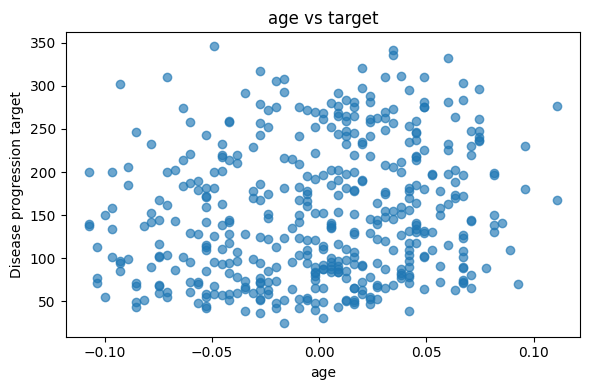

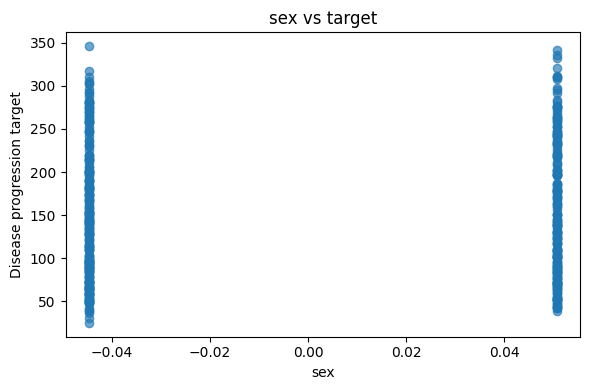

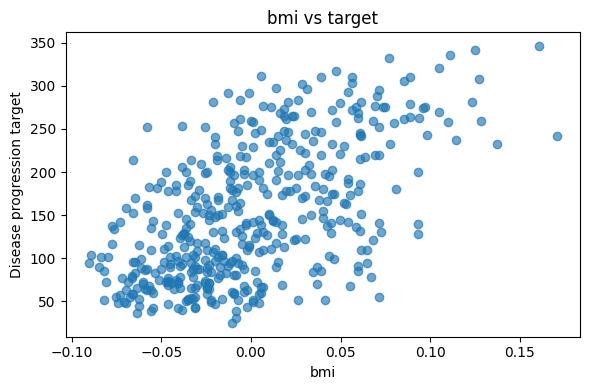

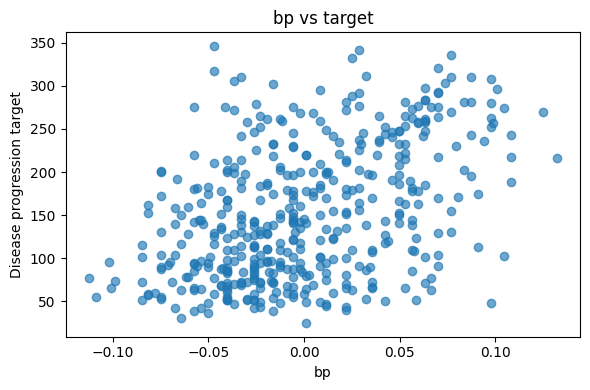

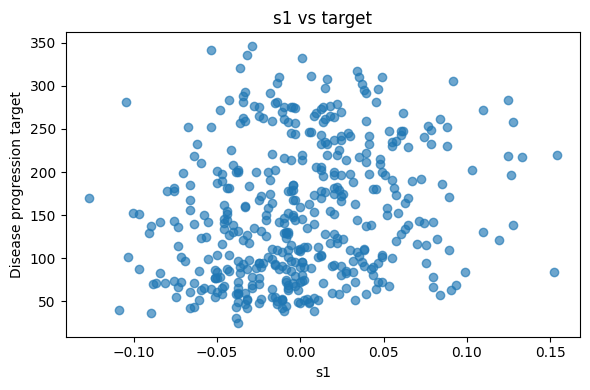

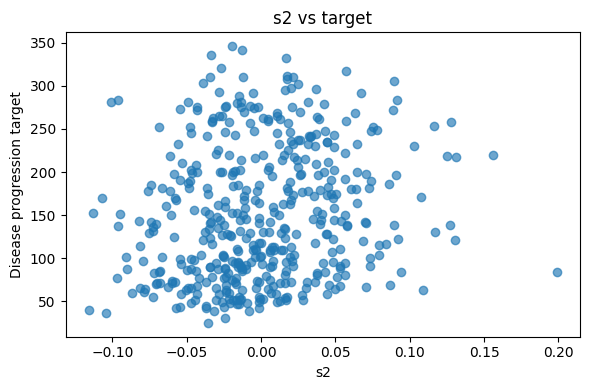

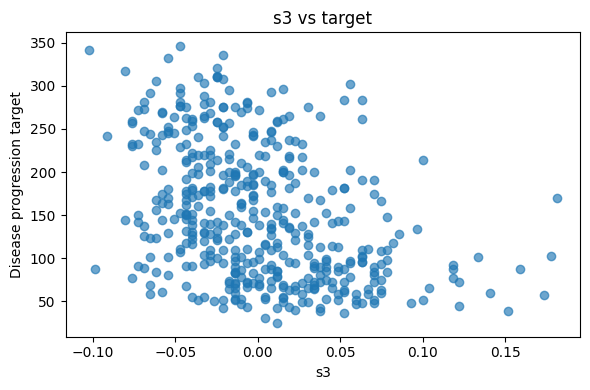

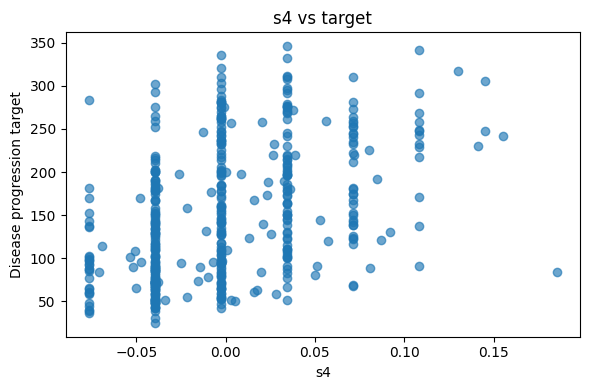

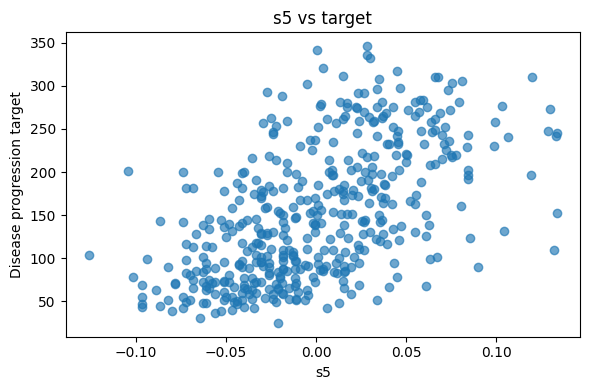

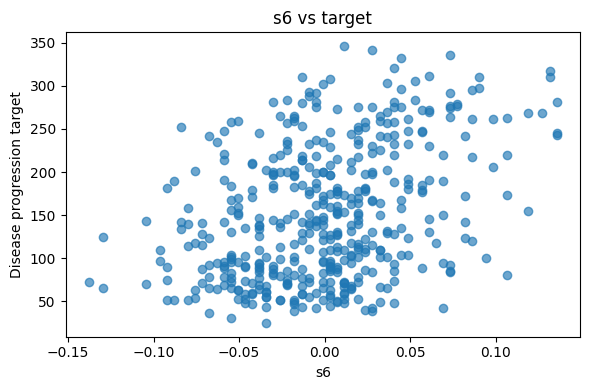

In [5]:
for feature in diabetes.feature_names:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[feature], df["target"], alpha=0.65)
    plt.xlabel(feature)
    plt.ylabel("Disease progression target")
    plt.title(f"{feature} vs target")
    plt.tight_layout()
    plt.show()

### 5.2 Correlation matrix and heatmap

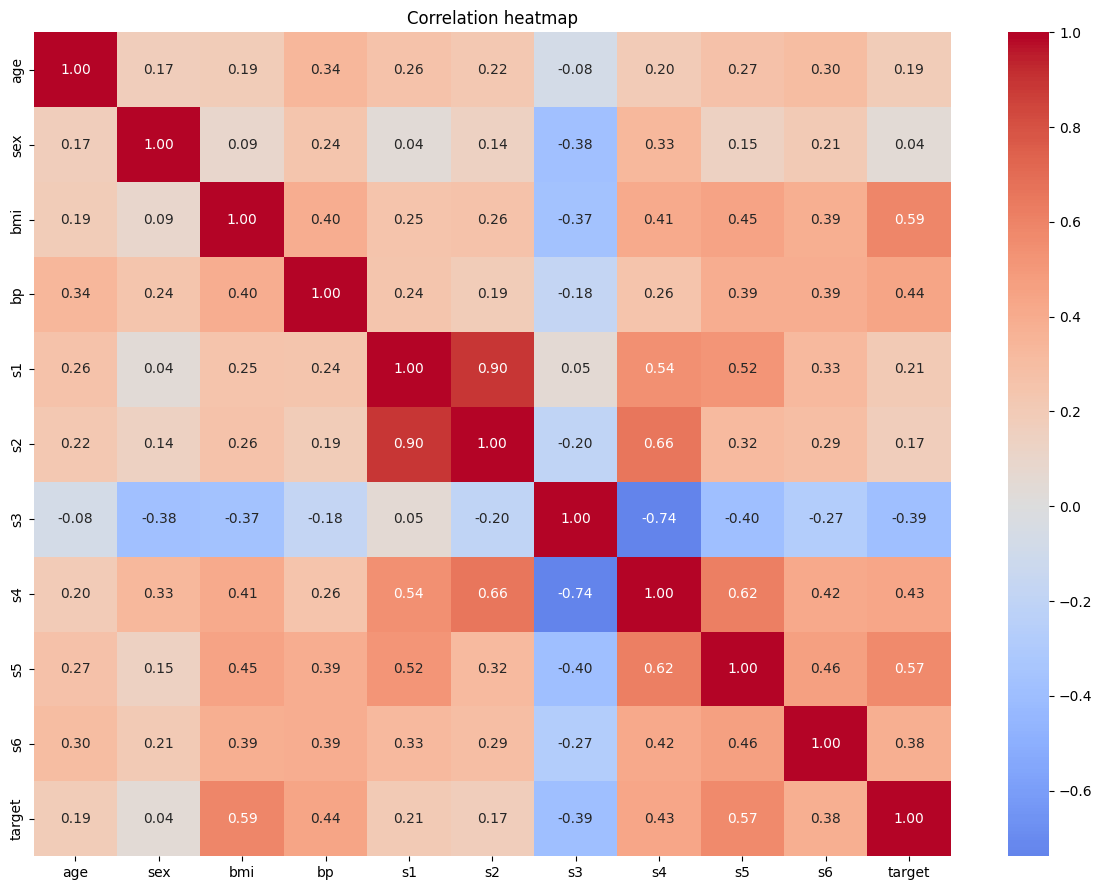

Feature correlations with target (sorted):


,target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


Note: correlation indicates association, not causation.


In [6]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print("Feature correlations with target (sorted):")
display(correlation["target"].drop("target").sort_values(key=np.abs, ascending=False))

print("Note: correlation indicates association, not causation.")

## 6. Manual multiple linear regression using two features

For a small sample, use two features (`bmi` and `s5`) and eight observations. The model is:

\[
\hat y = b_0 + b_1x_1 + b_2x_2
\]

The normal equation is \((X^TX)b = X^Ty\). The design matrix contains a column of ones for the intercept.


In [7]:
X1, X2 = "bmi", "s5"
sample = df[[X1, X2, "target"]].head(8).copy()

print("Selected observations:")
display(sample)

X_manual = np.column_stack([
    np.ones(len(sample)),
    sample[X1].to_numpy(),
    sample[X2].to_numpy()
])
y_manual = sample["target"].to_numpy()

print("Design matrix X:")
print(X_manual)
print("\nTarget vector y:")
print(y_manual)

XT_X = X_manual.T @ X_manual
XT_y = X_manual.T @ y_manual

print("\nX transpose X:")
print(XT_X)
print("\nX transpose y:")
print(XT_y)

manual_coefficients = np.linalg.lstsq(X_manual, y_manual, rcond=None)[0]
b0, b1, b2 = manual_coefficients

print("\nManual coefficients:")
print("b0 (intercept) =", b0)
print("b1 (bmi) =", b1)
print("b2 (s5) =", b2)
print(f"Equation: target = {b0:.4f} + ({b1:.4f} * bmi) + ({b2:.4f} * s5)")

manual_fitted = X_manual @ manual_coefficients
manual_residual = y_manual[0] - manual_fitted[0]
print("\nFirst observation actual:", y_manual[0])
print("First observation predicted:", manual_fitted[0])
print("First observation residual (actual - predicted):", manual_residual)

Selected observations:


,bmi,s5,target
0,0.061696,0.019907,151.0
1,-0.051474,-0.068332,75.0
2,0.044451,0.002861,141.0
3,-0.011595,0.022688,206.0
4,-0.036385,-0.031988,135.0
5,-0.040696,-0.041176,97.0
6,-0.047163,-0.062917,138.0
7,-0.001895,-0.035816,63.0


Design matrix X:
[[ 1.          0.06169621  0.01990749]
 [ 1.         -0.05147406 -0.06833155]
 [ 1.          0.04445121  0.00286131]
 [ 1.         -0.01159501  0.02268774]
 [ 1.         -0.03638469 -0.03198764]
 [ 1.         -0.04069594 -0.04117617]
 [ 1.         -0.04716281 -0.06291688]
 [ 1.         -0.00189471 -0.03581619]]

Target vector y:
[151.  75. 141. 206. 135.  97. 138.  63.]

X transpose X:
[[ 8.         -0.08305981 -0.19477188]
 [-0.08305981  0.01377428  0.0104844 ]
 [-0.19477188  0.0104844   0.01354845]]

X transpose y:
[1006.           -6.15265365  -16.29308452]

Manual coefficients:
b0 (intercept) = 158.1816535145207
b1 (bmi) = -750.3040586738384
b2 (s5) = 1652.0522919963282
Equation: target = 158.1817 + (-750.3041 * bmi) + (1652.0523 * s5)

First observation actual: 151.0
First observation predicted: 144.77894751457143
First observation residual (actual - predicted): 6.221052485428572


### Verify the manual calculation with Scikit-learn

`np.linalg.lstsq` solves the least-squares problem robustly. The library model below uses the same eight observations and the same two features, so the coefficients should agree apart from small floating-point differences.


In [8]:
manual_library_model = LinearRegression()
manual_library_model.fit(sample[[X1, X2]], sample["target"])

print("Manual intercept:", b0)
print("Library intercept:", manual_library_model.intercept_)
print("Manual coefficients:", [b1, b2])
print("Library coefficients:", manual_library_model.coef_)

print("Absolute intercept difference:",
      abs(b0 - manual_library_model.intercept_))
print("Absolute coefficient differences:",
      np.abs(np.array([b1, b2]) - manual_library_model.coef_))

Manual intercept: 158.1816535145207
Library intercept: 158.18165351452078
Manual coefficients: [np.float64(-750.3040586738384), np.float64(1652.0522919963282)]
Library coefficients: [-750.30405867 1652.052292  ]
Absolute intercept difference: 8.526512829121202e-14
Absolute coefficient differences: [2.27373675e-13 1.59161573e-12]


## 7. Train-test split

In [9]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target count:", len(y_train))
print("Testing target count:", len(y_test))

Training features shape: (353, 10)
Testing features shape: (89, 10)
Training target count: 353
Testing target count: 89


## 8. Single-feature baseline model

In [10]:
# Select the feature most strongly correlated with the target in the training set only.
train_correlations = X_train.join(y_train).corr(numeric_only=True)["target"].drop("target")
best_feature = train_correlations.abs().idxmax()

print("Selected single feature:", best_feature)
print("Training correlation:", train_correlations[best_feature])

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)

y_pred_single = single_model.predict(X_test[[best_feature]])

print("Single-feature intercept:", single_model.intercept_)
print("Single-feature coefficient:", single_model.coef_[0])
print("Single-feature test R2:", r2_score(y_test, y_pred_single))

Selected single feature: bmi
Training correlation: 0.6047512938220249
Single-feature intercept: 152.00335421448167
Single-feature coefficient: 998.5776891375598
Single-feature test R2: 0.23335039815872138


## 9. Multiple-feature linear regression

In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

y_pred_multiple = multiple_model.predict(X_test)

print("Multiple-feature intercept:", multiple_model.intercept_)
print("\nCoefficients:")
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(f"{feature}: {coefficient:.6f}")

equation = f"target = {multiple_model.intercept_:.4f}"
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    equation += f" + ({coefficient:.4f} × {feature})"
print("\nFitted equation:")
print(equation)

Multiple-feature intercept: 151.34560453985995

Coefficients:
age: 37.904021
sex: -241.964362
bmi: 542.428759
bp: 347.703844
s1: -931.488846
s2: 518.062277
s3: 163.419983
s4: 275.317902
s5: 736.198859
s6: 48.670657

Fitted equation:
target = 151.3456 + (37.9040 × age) + (-241.9644 × sex) + (542.4288 × bmi) + (347.7038 × bp) + (-931.4888 × s1) + (518.0623 × s2) + (163.4200 × s3) + (275.3179 × s4) + (736.1989 × s5) + (48.6707 × s6)


### Coefficient interpretation

Each coefficient estimates the change in the predicted target for a one-unit increase in that feature, **holding all other included features constant**. A positive coefficient indicates an increase in the prediction; a negative coefficient indicates a decrease. The intercept is the predicted target when all features equal zero, which may not represent a realistic record.

The dataset's features are already standardized by Scikit-learn, so their units are not the original clinical measurement units. Coefficients are associations, not causal effects.


## 10. Compare actual and predicted test values

In [12]:
prediction_comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Single-feature prediction": y_pred_single,
    "Multiple-feature prediction": y_pred_multiple
}, index=y_test.index)

display(prediction_comparison.head(10))

,Actual,Single-feature prediction,Multiple-feature prediction
287,219.0,145.806227,139.547558
211,70.0,188.857390,179.517208
72,202.0,147.958785,134.038756
321,230.0,203.925298,291.417029
73,111.0,131.814599,123.789659
418,84.0,127.509482,92.172347
367,242.0,322.315998,258.232389
354,272.0,197.467623,181.337321
281,94.0,61.856458,90.224113
148,96.0,167.331809,108.633759


## 11. Evaluate models using MAE, MSE, RMSE, R² and adjusted R²

In [13]:
def regression_metrics(y_true, y_pred, number_of_features):
    n = len(y_true)
    p = number_of_features
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adjusted_r2 = np.nan if n <= p + 1 else 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse,
            "R2": r2, "Adjusted R2": adjusted_r2}

single_results = regression_metrics(y_test, y_pred_single, 1)
multiple_results = regression_metrics(y_test, y_pred_multiple, X_train.shape[1])

results = pd.DataFrame(
    [single_results, multiple_results],
    index=["Single-feature model", "Multiple-feature model"]
)
display(results)

print("MAE: average absolute prediction error.")
print("MSE: average squared prediction error; larger errors receive more penalty.")
print("RMSE: square root of MSE, in target units.")
print("R2: comparison with predicting the test-set mean; it can be negative.")
print("Adjusted R2: adjusts R2 for the number of predictors.")

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature model,52.259976,4061.825928,63.732456,0.233350,0.224538
Multiple-feature model,42.794095,2900.193628,53.853446,0.452603,0.382424


MAE: average absolute prediction error.
MSE: average squared prediction error; larger errors receive more penalty.
RMSE: square root of MSE, in target units.
R2: comparison with predicting the test-set mean; it can be negative.
Adjusted R2: adjusts R2 for the number of predictors.


### Decide whether extra features helped

In [14]:
if multiple_results["R2"] > single_results["R2"] and multiple_results["RMSE"] < single_results["RMSE"]:
    print("The multiple-feature model performs better on both test R2 and RMSE.")
elif multiple_results["R2"] < single_results["R2"] and multiple_results["RMSE"] > single_results["RMSE"]:
    print("The single-feature model performs better on both test R2 and RMSE.")
else:
    print("The metrics give a mixed result. Consider the size of the improvement and model complexity.")

print("Compare test metrics, not training scores, when judging generalisation.")

The multiple-feature model performs better on both test R2 and RMSE.
Compare test metrics, not training scores, when judging generalisation.


## 12. Residual analysis

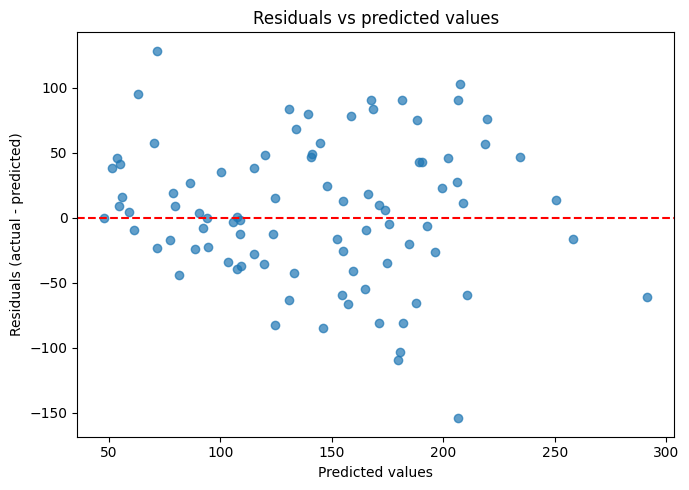

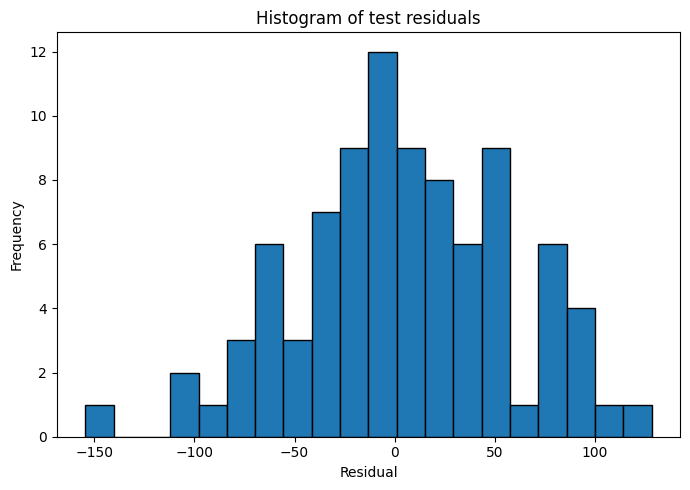

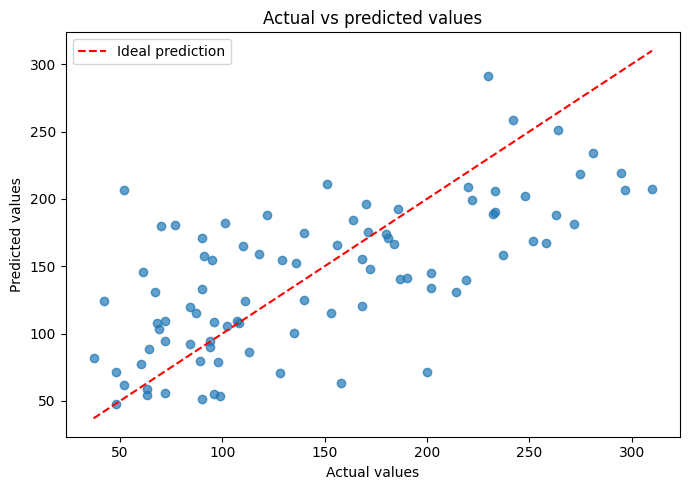

In [15]:
residuals = y_test.to_numpy() - y_pred_multiple

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_multiple, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted values")
plt.ylabel("Residuals (actual - predicted)")
plt.title("Residuals vs predicted values")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=20, edgecolor="black")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Histogram of test residuals")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_multiple, alpha=0.7)
lower = min(y_test.min(), y_pred_multiple.min())
upper = max(y_test.max(), y_pred_multiple.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Ideal prediction")
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs predicted values")
plt.legend()
plt.tight_layout()
plt.show()

### Residual interpretation

Residual = actual value − predicted value. A random cloud around zero is generally desirable. A curve can suggest non-linearity, and a funnel shape can suggest non-constant error variance. The histogram helps assess whether residuals are roughly symmetric; plots are diagnostic clues, not definitive proof of assumptions.


## 13. Multicollinearity check using VIF

In [16]:
# VIF is calculated on the training features. A constant is not included because
# the sklearn Diabetes features are already centred.
vif_values = []
for i, feature in enumerate(X_train.columns):
    vif_values.append(variance_inflation_factor(X_train.to_numpy(), i))

vif_table = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": vif_values
}).sort_values("VIF", ascending=False)

display(vif_table)

print("Rule of thumb: VIF near 1 indicates little linear redundancy;")
print("values above 5 may merit investigation and values above 10 are often considered high.")
print("These are guidelines, not strict universal cut-offs.")

,Feature,VIF
4,s1,55.252137
5,s2,35.759309
6,s3,14.285594
8,s5,10.071155
7,s4,9.333044
2,bmi,1.573561
9,s6,1.500654
3,bp,1.422084
1,sex,1.268854
0,age,1.217114


Rule of thumb: VIF near 1 indicates little linear redundancy;
values above 5 may merit investigation and values above 10 are often considered high.
These are guidelines, not strict universal cut-offs.


## 14. Standardized coefficients

In [17]:
# Standardize using training data only, then fit a model on the standardized features.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

standardized_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Standardized coefficient": scaled_model.coef_
}).sort_values("Standardized coefficient", key=np.abs, ascending=False)

display(standardized_coefficients)

print("Standardized coefficients express the change in target units for a one-standard-deviation")
print("increase in a feature, holding other standardized features constant.")

,Feature,Standardized coefficient
4,s1,-44.448856
8,s5,35.161195
2,bmi,25.607121
5,s2,24.640954
3,bp,16.828872
7,s4,13.138784
1,sex,-11.511809
6,s3,7.676978
9,s6,2.351364
0,age,1.753758


Standardized coefficients express the change in target units for a one-standard-deviation
increase in a feature, holding other standardized features constant.


## 15. Predict one new example

In [18]:
# Use the training-set median for each feature to create a plausible in-range example.
new_record = pd.DataFrame([X_train.median()], columns=X_train.columns)

print("New input record:")
display(new_record)

new_prediction = multiple_model.predict(new_record)[0]
print(f"Predicted target value: {new_prediction:.2f}")

# Check whether each feature is within the training range.
within_range = ((new_record.iloc[0] >= X_train.min()) &
                (new_record.iloc[0] <= X_train.max()))
print("\nFeature values within training ranges:")
display(within_range.to_frame("Within range"))

New input record:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.009016,-0.044642,-0.005128,-0.00567,-0.004321,-0.004132,-0.006584,-0.002592,-0.000612,0.003064


Predicted target value: 157.53

Feature values within training ranges:


,Within range
age,True
sex,True
bmi,True
bp,True
s1,True
s2,True
s3,True
s4,True
s5,True
s6,True


## 16. Final conclusion and decision log

In [19]:
print("FINAL MODEL SUMMARY")
print("-------------------")
print(f"Single-feature test R2: {single_results['R2']:.4f}")
print(f"Multiple-feature test R2: {multiple_results['R2']:.4f}")
print(f"Multiple-feature MAE: {multiple_results['MAE']:.4f}")
print(f"Multiple-feature RMSE: {multiple_results['RMSE']:.4f}")
print(f"Multiple-feature adjusted R2: {multiple_results['Adjusted R2']:.4f}")
print(f"New example prediction: {new_prediction:.2f}")

FINAL MODEL SUMMARY
-------------------
Single-feature test R2: 0.2334
Multiple-feature test R2: 0.4526
Multiple-feature MAE: 42.7941
Multiple-feature RMSE: 53.8534
Multiple-feature adjusted R2: 0.3824
New example prediction: 157.53
